# skin 집계방식 비교 — 증강 118개 포함(최대 659행) + 범위값(%) 처리 정책 민감도

**배경**: 직전 실험(`skin_aggregation_comparison_full_features.ipynb`)은 원본 NTP ICE 제형 544개(usable 541개)만으로 wmean/top/max/min 4가지 집계방식과 concat 조합을 비교했습니다. 결론: label A는 `min`, label B(팀 목표 라벨)는 `top`이 wmean보다 뚜렷이 좋았고, concat은 4개 목표 조합 전부에서 패배.

그 실험은 **원본 544개로 스코프가 한정**돼 있었습니다 — 집계방식을 재계산하려면 "제형별 성분 구성비(%)" 원자료가 필요한데, production 662행 중 원본 544개에만 그 원자료(`skin_filtered.csv`)가 있고 증강 118개는 이미 wmean으로 집계가 끝난 feature만 있다고 알려져 있었기 때문입니다.

**이번에 새로 확인한 것**: 증강 118개도 사실 성분 단위 원자료가 존재합니다 — `skin_보강후보_통합.xlsx`(v2/v3, 110건) · `skin_보강후보_v4_신규.xlsx`(v4, 1건)의 `성분함량` 시트, 그리고 팀원 공유 `skin_irritation_최종후보.xlsx`(B5배치, 7건)의 `V4성분검증` 시트. 다만 v2/v3 110건 중 일부 성분은 함량이 "35-40%" 같은 **범위**로만 적혀 있어("정확값" 없이 "하한"/"상한"만 있거나 자유텍스트에 범위로만 적힌 경우), 이를 숫자 하나로 바꾸는 규칙이 필요합니다. 이 노트북에서는 **중간값 / 하한 / 상한** 3가지 정책을 전부 비교합니다(참고: production이 지금 쓰는 `get_pct()` 함수는 이미 암묵적으로 중간값 정책을 씁니다 — 이 노트북의 "mid" 정책과 동일).

**이 노트북이 하는 일**:
1. 증강 118개 제형의 성분 단위 원자료를 3개 소스 파일에서 재구성하고, 범위값을 중간값/하한/상한으로 각각 숫자화.
2. 재구성한 원자료로 production의 wmean 집계값을 역산해 `skin_vectorized.csv`와 1e-6 이내로 일치하는지 검증(재구성 로직 자체의 정합성 확인).
3. 원본 541개(정책 무관, 그대로 재사용) + 증강 118개(정책별로 값이 달라짐)를 조합해 **"541단독" / "중간값(≈659행)" / "하한(≈659행)" / "상한(≈659행)"** 4가지 데이터셋 × wmean/top/max/min 4방식 × A/B라벨 × Extra Trees/RandomForest = **64개 조합**을 repeated group 5-fold CV(5시드)로 평가.
4. 확인할 것: (a) 659행으로 늘려도 "A는 min, B는 top" 결론이 유지되는지, (b) 범위값 처리 정책(중간값/하한/상한) 선택이 결과를 흔드는지.

| 항목 | 직전 실험 | 이 노트북 |
|---|---|---|
| 대상 제형 | 원본 544개(usable 541) | 원본 541 + 증강 118(usable 최대 108) ≈ 최대 659 |
| 범위값 처리 | 해당 없음(원본엔 범위 없음) | 중간값/하한/상한 3가지 비교 |
| feature | 공통8+desc217+fp2048 = 2,273차원 | 동일 |
| 모델 | Extra Trees(주) + RandomForest(참고) | 동일 |


## 0단계 — 데이터 로드 (원본 541개 원자료 + production 662행에서 증강 118개 메타데이터만)

In [1]:
import numpy as np
import pandas as pd

BASE = r"C:\Users\UserK\학술제\skin irritation"

# 원본 544개 제형의 성분 단위 원자료(함량%, casrn)
filt = pd.read_csv(rf"{BASE}\skin_filtered.csv")
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")
desc_full = pd.read_csv(rf"{BASE}\casrn_descriptors_full.csv").set_index("casrn")
FEATURE_COLS = list(desc_full.columns)
print("전체 feature 차원:", len(FEATURE_COLS))

known = filt.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc_full.index)
known = known.rename(columns={"casrn": "key", "percent_active_ingredient": "pct"})
known_unified = known[["formulation_id", "key", "pct", "has_descriptor"]].copy()
print("원본 제형 수(고유):", known_unified["formulation_id"].nunique())

# production(662행)에서 증강 118개의 formulation_id(AUG_ 접두사 제거)·라벨·comp_group_id만 재사용
# (augmented 행의 feature 컬럼은 이미 wmean 집계가 끝난 결과라 이번 실험에선 메타데이터만 쓰고,
#  feature는 3단계에서 성분 원자료로부터 직접 다시 계산함)
vec = pd.read_csv(rf"{BASE}\skin_vectorized.csv", low_memory=False)
aug_meta = vec.loc[vec["formulation_id"].astype(str).str.startswith("AUG_"),
                    ["formulation_id", "final_label", "comp_group_id"]].copy()
aug_meta["formulation_id"] = aug_meta["formulation_id"].str.replace("AUG_", "", regex=False)
print("증강 118개 메타 행 수:", len(aug_meta))
print("증강 final_label 분포:", aug_meta["final_label"].value_counts().sort_index().to_dict())


전체 feature 차원: 2273
원본 제형 수(고유): 544
증강 118개 메타 행 수: 118
증강 final_label 분포: {1.0: 4, 2.0: 3, 3.0: 14, 4.0: 97}


## 1단계 — 증강 118개 제형의 성분 단위 원자료 재구성 + 범위값 3정책 숫자화

소스 3개:
- `skin_보강후보_통합.xlsx`(`성분함량` 시트) — v2/v3 계열 110개 제형. 함량이 `정확값`(숫자) 또는 `하한`/`상한`(범위) 또는 `함량_원문`(자유텍스트, 그 안에 범위가 섞여 있기도 함)으로 기록돼 있음.
- `skin_보강후보_v4_신규.xlsx`(`성분함량` 시트) — v4:C002 1개 제형. 범위 없음(전부 정확값).
- 팀원 공유 `skin_irritation_최종후보.xlsx`(`V4성분검증` 시트) — B5배치 7개 제형(v4:B5_003/006/009/018, v4:C011/012/016). `parsed_exact_pct`로 이미 확정된 숫자라 정책과 무관.

**범위값 숫자화 규칙(`parse_bounds`)**: `pct_parser.py`(기존 production 파이프라인에서 이미 쓰는 파서)와 동일한 "불확실하면 추측하지 않고 포기" 원칙을 따르되, 중간값만 반환하던 기존 함수와 달리 하한/상한을 둘 다 반환하도록 확장함. `Inconsistency`/`garbled`/`International Units` 등 비율이 아닌 표시가 섞인 텍스트는 그대로 실패(NaN) 처리.

In [2]:
import re

SRC_B5 = r"C:\Users\UserK\OneDrive - 덕성여자대학교\문서\카카오톡 받은 파일\skin_irritation_최종후보.xlsx"

NUMBER = r"\d+(?:\.\d+)?"
RANGE_RE = re.compile(rf"^({NUMBER})[-~]({NUMBER})%?$")
NUM_RE = re.compile(rf"^({NUMBER})%?$")
OCR_RE = re.compile(rf"\(OCR for\s*({NUMBER})\s*%?\)")
UNRELIABLE_MARKERS = ["inconsistency", "garbled", "international units", "per mg of product"]
SUFFIXES = [" percent by weight", " percent", "% by weight", "% w/w", " w/w", "% a.i.", " a.i.", "%"]


def clean_text(text):
    cleaned = str(text).strip().replace(" ", "").replace(",", "").strip("*'")
    for suf in SUFFIXES:
        suf_clean = suf.replace(" ", "")
        if cleaned.lower().endswith(suf_clean.lower()):
            cleaned = cleaned[: -len(suf_clean)]
            break
    return cleaned.lstrip(".")


def parse_bounds(text):
    """(하한, 상한) 반환. 정확한 값이면 하한==상한. 파싱 불가/불확실 표시면 (None, None)."""
    if pd.isna(text):
        return None, None
    raw = str(text).strip()
    if any(m in raw.lower() for m in UNRELIABLE_MARKERS):
        return None, None
    m = OCR_RE.search(raw)
    if m:
        v = float(m.group(1))
        return v, v
    cleaned = clean_text(raw)
    if cleaned.count(".") > 1:
        return None, None
    try:
        m = RANGE_RE.match(cleaned)
        if m:
            return float(m.group(1)), float(m.group(2))
        m = NUM_RE.match(cleaned if cleaned.endswith("%") else cleaned + "%")
        if m:
            v = float(m.group(1))
            return v, v
        if re.fullmatch(NUMBER, cleaned):
            v = float(cleaned)
            return v, v
    except ValueError:
        return None, None
    return None, None


def resolve_pct_3way(row):
    if pd.notna(row.get("정확값")):
        v = float(row["정확값"])
        return {"mid": v, "lower": v, "upper": v}
    lo, hi = row.get("하한"), row.get("상한")
    if pd.notna(lo) and pd.notna(hi):
        lo, hi = float(lo), float(hi)
        return {"mid": (lo + hi) / 2, "lower": lo, "upper": hi}
    lo, hi = parse_bounds(row.get("함량_원문"))
    if lo is None:
        return {"mid": np.nan, "lower": np.nan, "upper": np.nan}
    return {"mid": (lo + hi) / 2, "lower": lo, "upper": hi}


B5_KEYS = ["v4:B5_003", "v4:B5_006", "v4:B5_009", "v4:B5_018", "v4:C011", "v4:C012", "v4:C016"]
all_aug_keys = aug_meta["formulation_id"].tolist()
v2v3_keys = [k for k in all_aug_keys if k.startswith("v2:") or k.startswith("v3:")]
v4_other_keys = [k for k in all_aug_keys if k.startswith("v4:") and k not in B5_KEYS]
print(f"v2/v3: {len(v2v3_keys)}개, v4(B5 제외): {v4_other_keys}, B5배치: {len(B5_KEYS)}개")

comp1 = pd.read_excel(rf"{BASE}\skin_보강후보_통합.xlsx", sheet_name="성분함량")
comp1 = comp1[comp1["후보키"].isin(v2v3_keys)].copy()
comp1["key"] = comp1["CAS_원문"].fillna(comp1["성분명_원문"])

comp2 = pd.read_excel(rf"{BASE}\skin_보강후보_v4_신규.xlsx", sheet_name="성분함량")
comp2 = comp2[comp2["후보키"].isin(v4_other_keys)].copy()
comp2["key"] = comp2["CAS_원문"].fillna(comp2["성분명_원문"])

ing_rows = []
for comp in (comp1, comp2):
    for _, r in comp.iterrows():
        pcts = resolve_pct_3way(r)
        ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], **pcts})

verif = pd.read_excel(SRC_B5, sheet_name="V4성분검증")
verif = verif[verif["후보키"].isin(B5_KEYS)].copy()
used = verif[verif["used"] == True].copy()  # noqa: E712
used["key"] = used["resolved_cas"].fillna(used["성분명_원문"])
for _, r in used.iterrows():
    v = float(r["parsed_exact_pct"])
    ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "mid": v, "lower": v, "upper": v})

ing = pd.DataFrame(ing_rows)
ing["has_descriptor"] = ing["key"].isin(desc_full.index)

print(f"\n총 성분행: {len(ing)} / 고유 제형 수: {ing['formulation_id'].nunique()} (기대 118)")
print("구조 해결 비율:", ing["has_descriptor"].mean().round(4))
n_zero = (ing.groupby("formulation_id")["has_descriptor"].sum() == 0).sum()
print(f"성분 전부 미해결이라 feature를 못 만드는 제형 수: {n_zero} (그룹 CV에서 자동 제외됨)")

diff_rows = ing[ing["mid"].notna() & (ing["lower"] != ing["upper"])]
print(f"정책 간 실제로 값이 다른(=진짜 범위) 성분행 수: {len(diff_rows)} / 영향받는 제형 수: {diff_rows['formulation_id'].nunique()}")


v2/v3: 110개, v4(B5 제외): ['v4:C002'], B5배치: 7개



총 성분행: 360 / 고유 제형 수: 118 (기대 118)
구조 해결 비율: 0.7111
성분 전부 미해결이라 feature를 못 만드는 제형 수: 10 (그룹 CV에서 자동 제외됨)
정책 간 실제로 값이 다른(=진짜 범위) 성분행 수: 47 / 영향받는 제형 수: 20


## 2단계 — 파이프라인 정합성 검증

재구성한 원자료로 **mid(중간값) 정책 기준 wmean**을 다시 계산해서, production `skin_vectorized.csv`에 이미 저장된 증강 118개 제형의 feature(공통 8개 descriptor 기준)와 1e-6 이내로 일치하는지 **118개 전부** 대조합니다. (직전 실험에서는 원본 544개에 대해 같은 방식으로 검증했었고, 이번엔 증강 118개 재구성 로직을 검증)

In [3]:
COMMON8 = ["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotatableBonds", "AromaticProportion", "ESOL_LogS"]
prod_indexed = vec.set_index("formulation_id")

errors = {}
for fid in ing["formulation_id"].unique():
    g = ing[(ing["formulation_id"] == fid) & (ing["has_descriptor"])]
    if len(g) == 0:
        continue
    pct = g["mid"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)
    d = desc_full.loc[g["key"], COMMON8].values
    mine = (pct[:, None] * d).sum(axis=0) / pct.sum()
    prod = prod_indexed.loc[f"AUG_{fid}", COMMON8].values.astype(float)
    errors[fid] = np.nanmax(np.abs(mine - prod))

err_series = pd.Series(errors)
print(f"대조 가능 제형 수: {len(err_series)} / 118")
print("최대 오차:", err_series.max())
print("오차 1e-6 초과 제형 수:", (err_series > 1e-6).sum())
if (err_series > 1e-6).sum() == 0:
    print("\n→ 전체 증강 118개 제형에서 mid 정책 wmean 재구성이 production과 1e-6 이내로 일치 — 재구성 로직 정합성 확인 완료.")


대조 가능 제형 수: 108 / 118


최대 오차: 2.2737367544323206e-13
오차 1e-6 초과 제형 수: 0

→ 전체 증강 118개 제형에서 mid 정책 wmean 재구성이 production과 1e-6 이내로 일치 — 재구성 로직 정합성 확인 완료.


## 3단계 — 집계 함수(wmean/top/max/min) + 정책별 659행 데이터셋 구성

`aggregate_group`은 직전 실험과 동일한 함수(원본/증강 모두 `{formulation_id, key, pct, has_descriptor}` 스키마로 통일했으므로 코드 변경 없이 재사용). `build_final_combined(method, policy)`는 policy에 따라:
- `orig541`: 원본 541개만 사용(직전 실험 재현 — 숫자가 그대로 나오면 이 노트북의 파이프라인이 올바르다는 추가 증거가 됨)
- `mid`/`lower`/`upper`: 원본 541개 + 증강 118개(해당 정책의 % 값 적용)를 합쳐 최대 659행 구성

In [4]:
def aggregate_group(g_resolved, method):
    d = desc_full.loc[g_resolved["key"]].values
    pct = g_resolved["pct"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)
    if method == "wmean":
        return (pct[:, None] * d).sum(axis=0) / pct.sum()
    elif method == "top":
        idx = int(np.argmax(pct))
        return d[idx]
    elif method == "max":
        return d.max(axis=0)
    elif method == "min":
        return d.min(axis=0)
    else:
        raise ValueError(method)


combined_labels = pd.concat(
    [labels[["formulation_id", "final_label", "comp_group_id"]], aug_meta],
    ignore_index=True,
)


def raw_table(policy):
    if policy == "orig541":
        return known_unified
    aug_unified = ing.rename(columns={policy: "pct"})[["formulation_id", "key", "pct", "has_descriptor"]]
    return pd.concat([known_unified, aug_unified], ignore_index=True)


def build_final_combined(method, policy):
    raw = raw_table(policy)
    rows = []
    for fid, grp in raw.groupby("formulation_id"):
        g_resolved = grp[grp["has_descriptor"]]
        if len(g_resolved) > 0:
            v = aggregate_group(g_resolved, method)
            row = {"formulation_id": fid, **dict(zip(FEATURE_COLS, v))}
        else:
            row = {"formulation_id": fid, **{c: np.nan for c in FEATURE_COLS}}
        rows.append(row)
    agg = pd.DataFrame(rows)
    comp_count = raw.groupby("formulation_id")["key"].nunique().rename("comp_count").reset_index()
    out = agg.merge(comp_count, on="formulation_id", how="left")
    out = out.merge(combined_labels, on="formulation_id", how="left", validate="one_to_one")
    out["binary_label_A"] = out["final_label"].map(lambda x: 1 if x in (1, 2) else 0)
    out["binary_label_B"] = out["final_label"].map(lambda x: 1 if x in (1, 2, 3) else 0)
    return out


METHODS = ["wmean", "top", "max", "min"]
POLICIES = ["orig541", "mid", "lower", "upper"]
finals2 = {(m, p): build_final_combined(m, p) for m in METHODS for p in POLICIES}
for p in POLICIES:
    shp = finals2[("wmean", p)].shape
    n_feat_ok = finals2[("wmean", p)][FEATURE_COLS].notna().all(axis=1).sum()
    print(f"policy={p}: 전체 {shp[0]}행, feature 계산 성공(usable) {n_feat_ok}행")


policy=orig541: 전체 544행, feature 계산 성공(usable) 541행
policy=mid: 전체 662행, feature 계산 성공(usable) 646행
policy=lower: 전체 662행, feature 계산 성공(usable) 646행
policy=upper: 전체 662행, feature 계산 성공(usable) 646행


## 4단계 — 64개 조합(4방식 × 2라벨 × 2모델 × 4데이터셋) repeated group 5-fold CV

직전 실험과 동일한 `grouped_cv`(StratifiedGroupKFold 5-fold × 5시드, comp_group_id로 그룹 분리해 조성 쌍둥이 누수 방지, ExtraTrees/RandomForest 둘 다 `n_estimators=500, class_weight=balanced*`)를 그대로 재사용합니다.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix

MODELS = {
    "ExtraTrees": lambda seed: ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
    "RandomForest": lambda seed: RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
}


def grouped_cv(df, feature_cols, label_col, model_name, n_splits=5, seeds=range(5)):
    ok = df[feature_cols].notna().all(axis=1).values
    X = df.loc[ok, feature_cols].values
    y = df.loc[ok, label_col].values
    g = df.loc[ok, "comp_group_id"].astype(str).values

    rows = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        oof = np.zeros(len(y))
        for tr, te in cv.split(X, y, g):
            assert set(g[tr]).isdisjoint(g[te]), "그룹 누수 발생"
            m = MODELS[model_name](s).fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
        pred05 = (oof >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred05).ravel()
        rows.append({
            "seed": s,
            "roc_auc": roc_auc_score(y, oof),
            "pr_auc": average_precision_score(y, oof),
            "mcc": matthews_corrcoef(y, pred05),
            "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
            "specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        })
    return pd.DataFrame(rows), int(ok.sum()), int(y.sum())


results2 = []
per_seed2 = {}
for label_name, label_col in [("A", "binary_label_A"), ("B", "binary_label_B")]:
    for model_name in MODELS:
        for policy in POLICIES:
            for m in METHODS:
                df = finals2[(m, policy)]
                r, n_used, n_pos = grouped_cv(df, FEATURE_COLS, label_col, model_name)
                key = (label_name, model_name, policy, m)
                per_seed2[key] = r
                results2.append({
                    "label": label_name, "model": model_name, "policy": policy, "method": m,
                    "n_used": n_used, "n_pos": n_pos,
                    "roc_auc_mean": r.roc_auc.mean(), "roc_auc_std": r.roc_auc.std(),
                    "pr_auc_mean": r.pr_auc.mean(), "pr_auc_std": r.pr_auc.std(),
                    "mcc_mean": r.mcc.mean(), "mcc_std": r.mcc.std(),
                    "sensitivity_mean": r.sensitivity.mean(), "specificity_mean": r.specificity.mean(),
                })
                print(f"완료: label={label_name} model={model_name} policy={policy} method={m} (n={n_used}, pos={n_pos})")

result_table2 = pd.DataFrame(results2)
result_table2.to_csv(rf"{BASE}\skin_aggregation_range_policy_full_results.csv", index=False, encoding="utf-8-sig")
print("\n저장:", rf"{BASE}\skin_aggregation_range_policy_full_results.csv")


완료: label=A model=ExtraTrees policy=orig541 method=wmean (n=541, pos=30)


완료: label=A model=ExtraTrees policy=orig541 method=top (n=541, pos=30)


완료: label=A model=ExtraTrees policy=orig541 method=max (n=541, pos=30)


완료: label=A model=ExtraTrees policy=orig541 method=min (n=541, pos=30)


완료: label=A model=ExtraTrees policy=mid method=wmean (n=646, pos=35)


완료: label=A model=ExtraTrees policy=mid method=top (n=649, pos=35)


... (54 outputs left out)

완료: label=B model=RandomForest policy=upper method=wmean (n=646, pos=114)


완료: label=B model=RandomForest policy=upper method=top (n=649, pos=115)


완료: label=B model=RandomForest policy=upper method=max (n=646, pos=114)


완료: label=B model=RandomForest policy=upper method=min (n=646, pos=114)

저장: C:\Users\UserK\학술제\skin irritation\skin_aggregation_range_policy_full_results.csv


## 5단계 — "541단독" vs "659(중간값 정책)" 비교: 결론이 유지되는가

직전 실험(원본 541개 단독)의 결론은 **label A → min 최고, label B(팀 목표) → top 최고**였습니다. 증강 118개를 추가한 659행(mid 정책)에서도 같은 방식이 1위인지, 그리고 그때 MCC가 어떻게 바뀌는지 확인합니다.

                          mcc_mean         mcc_std         n_used        
policy                         mid orig541     mid orig541    mid orig541
label model        method                                                
A     ExtraTrees   max       0.154   0.154   0.056   0.018  646.0   541.0
                   min       0.178   0.213   0.028   0.012  646.0   541.0
                   top       0.150   0.131   0.026   0.020  649.0   541.0
                   wmean     0.158   0.170   0.050   0.028  646.0   541.0
      RandomForest max       0.203   0.205   0.069   0.045  646.0   541.0
                   min       0.250   0.322   0.075   0.042  646.0   541.0
                   top       0.222   0.206   0.024   0.049  649.0   541.0
                   wmean     0.153   0.251   0.066   0.035  646.0   541.0
B     ExtraTrees   max       0.218   0.236   0.029   0.028  646.0   541.0
                   min       0.214   0.210   0.029   0.018  646.0   541.0
                   top       0.199   0

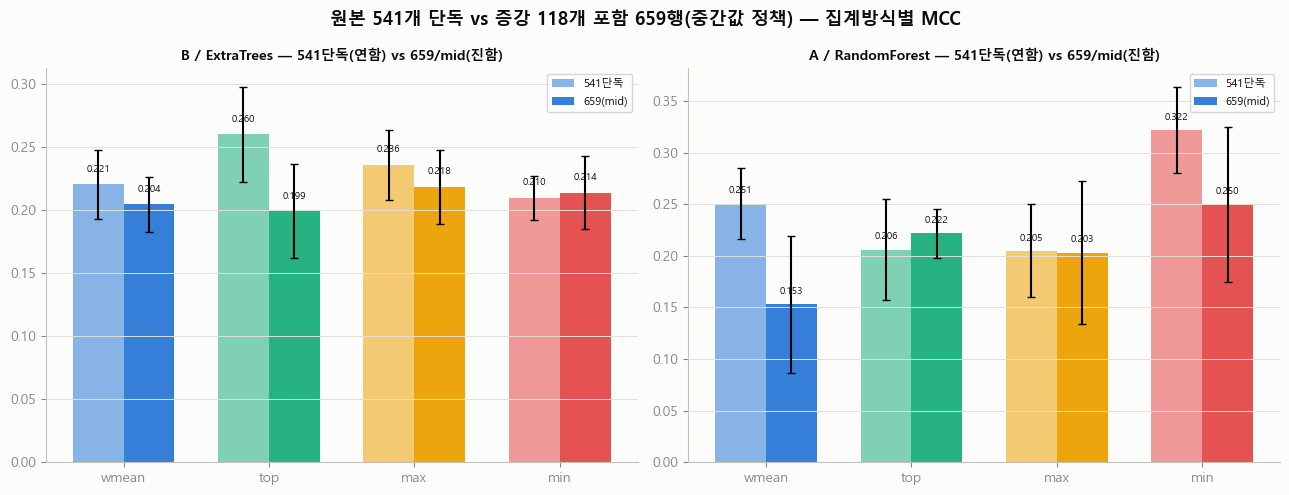

In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"
COLORS = {"wmean": "#2a78d6", "top": "#1baf7a", "max": "#eda100", "min": "#e34948"}

pd.set_option("display.width", 140)
compare_541_vs_659 = result_table2[result_table2.policy.isin(["orig541", "mid"])].pivot_table(
    index=["label", "model", "method"], columns="policy", values=["mcc_mean", "mcc_std", "n_used"]
)
print(compare_541_vs_659.round(3))

fig4, axes4 = plt.subplots(1, 2, figsize=(13, 5), facecolor=SURFACE)
for ax, label_name, model_name in zip(axes4, ["B", "A"], ["ExtraTrees", "RandomForest"]):
    ax.set_facecolor(SURFACE)
    sub = result_table2[(result_table2.label == label_name) & (result_table2.model == model_name)
                         & (result_table2.policy.isin(["orig541", "mid"]))]
    x = np.arange(len(METHODS))
    w = 0.35
    for i, policy in enumerate(["orig541", "mid"]):
        s = sub[sub.policy == policy].set_index("method").loc[METHODS]
        bars = ax.bar(x + (i - 0.5) * w, s["mcc_mean"], width=w, yerr=s["mcc_std"], capsize=3,
                       label="541단독" if policy == "orig541" else "659(mid)",
                       color=[COLORS[m] for m in METHODS], alpha=0.55 if policy == "orig541" else 0.95)
        for b, mean in zip(bars, s["mcc_mean"]):
            ax.text(b.get_x() + b.get_width() / 2, mean + 0.01, f"{mean:.3f}", ha="center", fontsize=7, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(METHODS)
    ax.set_title(f"{label_name} / {model_name} — 541단독(연함) vs 659/mid(진함)", fontsize=10, color=INK, fontweight="bold")
    ax.legend(fontsize=8)
    ax.tick_params(colors=MUTED)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
    ax.spines["left"].set_color(BASE_C)
    ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)

fig4.suptitle("원본 541개 단독 vs 증강 118개 포함 659행(중간값 정책) — 집계방식별 MCC", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_aggregation_541_vs_659_mcc.png", dpi=150, facecolor=SURFACE)
plt.show()


## 6단계 — 범위값 처리 정책(중간값/하한/상한) 민감도 — 659행 한정

같은 659행 데이터셋 안에서 증강 118개의 범위값을 중간값 대신 하한 또는 상한으로 바꿨을 때, 집계방식별 MCC가 얼마나 흔들리는지 확인합니다. (영향받는 제형은 20개 내외뿐이므로 큰 변화는 예상하지 않지만, 숫자로 확인합니다.)

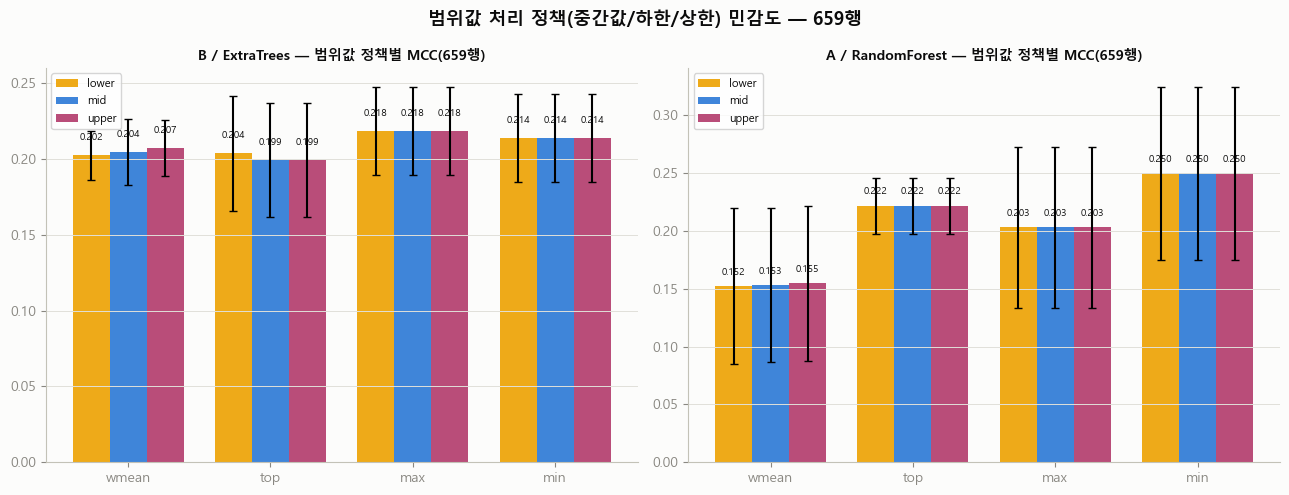


정책 간 최대 MCC 차이(같은 label/model/method 안에서 lower~upper 범위):
label        model method  policy_mcc_spread
    A   ExtraTrees  wmean             0.0071
    B   ExtraTrees  wmean             0.0048
    B   ExtraTrees    top             0.0043
    B RandomForest  wmean             0.0036
    A RandomForest  wmean             0.0026
    B RandomForest    top             0.0019
    A   ExtraTrees    top             0.0014
    A   ExtraTrees    min             0.0000
    A RandomForest    top             0.0000
    A RandomForest    min             0.0000
    A RandomForest    max             0.0000
    A   ExtraTrees    max             0.0000
    B   ExtraTrees    max             0.0000
    B   ExtraTrees    min             0.0000
    B RandomForest    min             0.0000
    B RandomForest    max             0.0000


In [7]:
fig5, axes5 = plt.subplots(1, 2, figsize=(13, 5), facecolor=SURFACE)
policy_colors = {"mid": "#2a78d6", "lower": "#eda100", "upper": "#b23a6b"}

for ax, label_name, model_name in zip(axes5, ["B", "A"], ["ExtraTrees", "RandomForest"]):
    ax.set_facecolor(SURFACE)
    sub = result_table2[(result_table2.label == label_name) & (result_table2.model == model_name)
                         & (result_table2.policy.isin(["mid", "lower", "upper"]))]
    x = np.arange(len(METHODS))
    w = 0.26
    for i, policy in enumerate(["lower", "mid", "upper"]):
        s = sub[sub.policy == policy].set_index("method").loc[METHODS]
        bars = ax.bar(x + (i - 1) * w, s["mcc_mean"], width=w, yerr=s["mcc_std"], capsize=3,
                       label=policy, color=policy_colors[policy], alpha=0.9)
        for b, mean in zip(bars, s["mcc_mean"]):
            ax.text(b.get_x() + b.get_width() / 2, mean + 0.01, f"{mean:.3f}", ha="center", fontsize=7, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(METHODS)
    ax.set_title(f"{label_name} / {model_name} — 범위값 정책별 MCC(659행)", fontsize=10, color=INK, fontweight="bold")
    ax.legend(fontsize=8)
    ax.tick_params(colors=MUTED)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
    ax.spines["left"].set_color(BASE_C)
    ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)

fig5.suptitle("범위값 처리 정책(중간값/하한/상한) 민감도 — 659행", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_aggregation_range_policy_sensitivity.png", dpi=150, facecolor=SURFACE)
plt.show()

print("\n정책 간 최대 MCC 차이(같은 label/model/method 안에서 lower~upper 범위):")
spread = result_table2[result_table2.policy.isin(["mid", "lower", "upper"])].groupby(
    ["label", "model", "method"]
)["mcc_mean"].agg(lambda s: s.max() - s.min()).rename("policy_mcc_spread").reset_index()
print(spread.sort_values("policy_mcc_spread", ascending=False).round(4).to_string(index=False))


## 7단계 — 결론

In [8]:
print("=" * 70)
print("(a) 659행 확장 후에도 541단독 결론이 유지되는가")
print("=" * 70)
for label_name, model_name in [("B", "ExtraTrees"), ("A", "RandomForest")]:
    sub541 = result_table2[(result_table2.label == label_name) & (result_table2.model == model_name)
                            & (result_table2.policy == "orig541")]
    sub659 = result_table2[(result_table2.label == label_name) & (result_table2.model == model_name)
                            & (result_table2.policy == "mid")]
    best541 = sub541.loc[sub541["mcc_mean"].idxmax()]
    best659 = sub659.loc[sub659["mcc_mean"].idxmax()]
    same = "유지됨" if best541["method"] == best659["method"] else "바뀜"
    print(f"{label_name}/{model_name}: 541단독 1위={best541['method']}(MCC {best541['mcc_mean']:.3f}) "
          f"-> 659/mid 1위={best659['method']}(MCC {best659['mcc_mean']:.3f}) [{same}]")

print()
print("=" * 70)
print("(b) 범위값 정책(중간값/하한/상한) 선택이 결과를 흔드는가")
print("=" * 70)
noise_by_combo = result_table2[result_table2.policy.isin(["mid", "lower", "upper"])].groupby(
    ["label", "model", "method"]
)["mcc_std"].mean()
spread_vs_noise = spread.set_index(["label", "model", "method"])["policy_mcc_spread"] - noise_by_combo
worst = spread_vs_noise.idxmax()
print(f"정책 간 변동폭이 fold-seed 변동폭(mcc_std)보다 큰 조합 수: {(spread_vs_noise > 0).sum()} / {len(spread_vs_noise)}")
print(f"가장 민감한 조합: {worst} (정책 변동폭 {spread.set_index(['label','model','method']).loc[worst, 'policy_mcc_spread']:.4f}"
      f" vs 평균 mcc_std {noise_by_combo.loc[worst]:.4f})")
if (spread_vs_noise > 0).sum() == 0:
    print("\n→ 모든 조합에서 범위값 정책(중간값/하한/상한) 선택에 따른 MCC 변동이 fold-seed 노이즈보다 작습니다."
          " 즉, 어떤 정책을 쓰든 결과에 실질적인 영향은 없습니다 — 중간값(=현재 production 기본값) 유지가 안전합니다.")
else:
    print("\n→ 일부 조합에서는 정책 변동폭이 노이즈보다 큽니다 — 해당 조합에 한해 정책 선택을 더 신중히 볼 필요가 있습니다.")


(a) 659행 확장 후에도 541단독 결론이 유지되는가
B/ExtraTrees: 541단독 1위=top(MCC 0.260) -> 659/mid 1위=max(MCC 0.218) [바뀜]
A/RandomForest: 541단독 1위=min(MCC 0.322) -> 659/mid 1위=min(MCC 0.250) [유지됨]

(b) 범위값 정책(중간값/하한/상한) 선택이 결과를 흔드는가
정책 간 변동폭이 fold-seed 변동폭(mcc_std)보다 큰 조합 수: 0 / 16
가장 민감한 조합: ('B', 'ExtraTrees', 'wmean') (정책 변동폭 0.0048 vs 평균 mcc_std 0.0188)

→ 모든 조합에서 범위값 정책(중간값/하한/상한) 선택에 따른 MCC 변동이 fold-seed 노이즈보다 작습니다. 즉, 어떤 정책을 쓰든 결과에 실질적인 영향은 없습니다 — 중간값(=현재 production 기본값) 유지가 안전합니다.


## 한계점

1. 증강 118개 중 실제로 범위값의 영향을 받는 제형은 약 20개뿐이라, 정책 민감도 테스트 자체의 통계적 검정력은 크지 않습니다(영향받는 표본이 적음).
2. 증강 118개 중 10개는 모든 성분의 구조(CAS→SMILES)가 미해결이라 feature를 만들 수 없어 자동 제외됩니다(= 659행이 아니라 최대 649행 내외가 실제 usable).
3. 이 노트북은 production의 라벨(`final_label`)과 `comp_group_id`는 그대로 신뢰하고 재사용합니다 — 라벨 자체의 정확성(EPA 등급 산정 근거)은 이번 검증 범위 밖입니다.
4. 범위값 정책 민감도가 낮게 나오더라도, 이는 "이번 모델·이번 CV 설정에서" 그렇다는 것이며, 더 작은 표본이나 다른 모델에서는 다를 수 있습니다.
